In [1]:
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor, early_stopping
import optuna
import sys
from pathlib import Path
from dataclasses import replace
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 987
TRACK = "list_aware"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 100                             # optuna trials per segment
ES_FRACTION = 0.0                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # CV validates on each of the last K_FOLDS months before VAL_START
META_MONTHS = 12                          # out-of-fold predictions for the meta model also cover the last META_MONTHS months before VAL_START
MODEL_NAME = "lightgbm_split_apartment"  # file name in oof_preds/<TRACK>/, change it for each model you want in the ensemble
DEBUG = True                             # print MdAPE and MAPE for every fold
SEGMENTS = {"apartment": 1, "house": 0}  # segment name -> is_apartment value

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [4]:
from xxbonkxx_features import off_market_features, list_aware_features, make_is_apartment

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

is_apartment = make_is_apartment(listings)

# Column names only. The matrices are built inside each fold, then again on train and val after tuning.
print(f"Features: {make_features(train.iloc[:10]).columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()} ({is_apartment[train.index].sum():,} apartments)")
print(f"val:   {len(val):,} sales from {VAL_START.date()} ({is_apartment[val.index].sum():,} apartments)")

Features: ['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment', 'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1', 'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1', 'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1', 'is_apartment_x_parking_0', 'is_apartment_x_parking_1', 'square_feet_x_bedrooms', 'square_feet_x_washrooms', 'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking', 'washrooms_x_parking', 'month_sin', 'month_cos', 'lag_annual', 'lag_semi_annual', 'building_sales', 'building_log_ppsf', 'building_log_price', 'building_last_log_ppsf', 'building_days_since_sale', 'repeat_log_price', 'repeat_days_since_sale', 'remarks_renovated', 'remarks_updated', 'remarks_turnkey', 'remarks_kitchen', 'remarks_premium_kitchen', 'remarks_wood_floor', 'remarks_clean', 'remarks_needs_work', 'remarks_dated', 'remarks_split_be

In [5]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [6]:
from training_utils import walk_forward_folds

CATEGORICAL_FEATURES = [
        "community",
        "house_style",
        "house_type",
    ]


def cv_months(K, end=VAL_START):
    """The K calendar months just before `end`, oldest first."""
    return pd.period_range(end=(end - pd.Timedelta(days=1)).to_period("M"), periods=K, freq="M")


def segment_fold(fold, is_apartment):
    """The part of a walk-forward fold whose homes have the given is_apartment value, in
    both the training sales and the predicted month. The is_apartment columns (and their
    interactions) are constant within a segment, so they are dropped."""
    in_train = fold.X_train["is_apartment"].astype(int) == is_apartment
    in_homes = fold.X_homes["is_apartment"].astype(int) == is_apartment
    apartment_columns = [col for col in fold.X_train.columns if col.startswith("is_apartment")]
    return replace(
        fold,
        homes=fold.homes.loc[in_homes[in_homes].index],
        X_train=fold.X_train.loc[in_train].drop(columns=apartment_columns),
        y_train=fold.y_train.loc[in_train],
        X_homes=fold.X_homes.loc[in_homes].drop(columns=apartment_columns),
    )


def cross_val(folds, y, params, debug=False, target_space="log"):
    """Monthly walk-forward CV, the way `python run.py validate` works: each fold
    predicts one month's sales (answers hidden) with a model trained on every earlier sale.
    `folds` comes from walk_forward_folds, so features are built once, not per trial.
    `y` is indexed like the homes the folds were built from. Early stopping uses the
    latest ES_FRACTION of each fold's training rows, never the validated month.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold in folds:
        X_tr, X_va = fold.X_train, fold.X_homes
        n_fit = int(len(X_tr) * (1 - ES_FRACTION))
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit, y_es, y_va = y.loc[X_fit.index], y.loc[X_es.index], y.loc[X_va.index]

        model = LGBMRegressor(**params, random_state=SEED, verbosity=-1)
        model.fit(X_fit, y_fit, categorical_feature=CATEGORICAL_FEATURES)
        rounds.append(model.best_iteration_)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
            mape_scores.append(mape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))
            mape_scores.append(mape(y_va, pred))

        if debug:
            mdape_error = mdape_scores[-1]
            mape_error = mape_scores[-1]
            print(f"{fold.month}: train {len(X_fit):,}  early stop {len(X_es):,}  val {len(X_va):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_error:.2f}%  MAPE {mape_error:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [7]:
# Built once and shared by every trial of both segments: the last K_FOLDS months before VAL_START.
cv_folds = walk_forward_folds(train, make_features, TRACK, months=cv_months(K_FOLDS))
print("CV months:", ", ".join(str(fold.month) for fold in cv_folds))

segment_cv_folds = {
    segment: [segment_fold(fold, flag) for fold in cv_folds]
    for segment, flag in SEGMENTS.items()
}

def make_objective(folds):
    def objective(trial):
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255),
            "max_depth": trial.suggest_int("max_depth", 3, 13),
            "n_estimators": trial.suggest_int("n_estimators", 200, 2000, step=200),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "min_split_gain": trial.suggest_float("min_split_gain", 0, 0.1, step=0.01),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            "metric": "mae",
            "device": "gpu"
        }
        score, n_rounds = cross_val(folds, y_train, params, debug=DEBUG, target_space=target_space)
        trial.set_user_attr("n_rounds", n_rounds)
        return score
    return objective

CV months: 2025-07, 2025-08, 2025-09, 2025-10, 2025-11


In [8]:
studies = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        study_name=f"lightgbm_{segment}",
    )
    study.optimize(make_objective(segment_cv_folds[segment]), n_trials=N_TRIALS)
    studies[segment] = study

for segment, study in studies.items():
    print(f"\n{segment}")
    print("  best CV MdAPE:", round(study.best_value, 2))
    print("  best params:", study.best_params)
    print("  boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-11-05 14:08:53,955] A new study created in memory with name: lightgbm_apartment



===== apartment (is_apartment = 1) =====
2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 3.38%  MAPE 4.20%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 3.60%  MAPE 4.38%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 3.62%  MAPE 4.41%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 3.25%  MAPE 3.97%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 3.51%  MAPE 4.22%
mean MdAPE 3.47%  mean MAPE 4.23%


[I 2026-11-05 14:09:23,881] Trial 0 finished with value: 3.471398428985895 and parameters: {'learning_rate': 0.05, 'num_leaves': 109, 'max_depth': 12, 'n_estimators': 1000, 'colsample_bytree': 0.9, 'min_child_samples': 93, 'min_split_gain': 0.1, 'reg_lambda': 7.103714746188992, 'reg_alpha': 0.0013187949354214168}. Best is trial 0 with value: 3.471398428985895.


2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 3.38%  MAPE 4.35%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 3.76%  MAPE 4.46%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 3.55%  MAPE 4.35%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 3.39%  MAPE 3.99%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 3.41%  MAPE 4.18%
mean MdAPE 3.50%  mean MAPE 4.27%


[I 2026-11-05 14:10:21,820] Trial 1 finished with value: 3.4967120978161987 and parameters: {'learning_rate': 0.01, 'num_leaves': 223, 'max_depth': 3, 'n_estimators': 1600, 'colsample_bytree': 0.8, 'min_child_samples': 34, 'min_split_gain': 0.02, 'reg_lambda': 1.1275113496020217, 'reg_alpha': 4.791227993546376}. Best is trial 0 with value: 3.471398428985895.


2025-07: train 76,469  early stop 0  val 1,115  rounds 0  MdAPE 3.33%  MAPE 4.26%
2025-08: train 77,584  early stop 0  val 951  rounds 0  MdAPE 3.58%  MAPE 4.41%
2025-09: train 78,535  early stop 0  val 1,039  rounds 0  MdAPE 3.66%  MAPE 4.44%
2025-10: train 79,574  early stop 0  val 1,193  rounds 0  MdAPE 3.40%  MAPE 4.02%
2025-11: train 80,767  early stop 0  val 989  rounds 0  MdAPE 3.46%  MAPE 4.21%
mean MdAPE 3.48%  mean MAPE 4.27%


... (392 outputs left out)

[I 2026-11-05 20:25:46,053] Trial 98 finished with value: 5.262512554862839 and parameters: {'learning_rate': 0.03, 'num_leaves': 240, 'max_depth': 9, 'n_estimators': 2000, 'colsample_bytree': 0.4, 'min_child_samples': 29, 'min_split_gain': 0.0, 'reg_lambda': 0.04248971831524395, 'reg_alpha': 3.469318646788946}. Best is trial 57 with value: 5.117521102577137.


2025-07: train 53,576  early stop 0  val 953  rounds 0  MdAPE 5.31%  MAPE 6.70%
2025-08: train 54,529  early stop 0  val 715  rounds 0  MdAPE 5.29%  MAPE 6.37%
2025-09: train 55,244  early stop 0  val 996  rounds 0  MdAPE 4.84%  MAPE 6.05%
2025-10: train 56,240  early stop 0  val 1,057  rounds 0  MdAPE 4.96%  MAPE 5.97%
2025-11: train 57,297  early stop 0  val 878  rounds 0  MdAPE 5.28%  MAPE 6.52%
mean MdAPE 5.14%  mean MAPE 6.32%


[I 2026-11-05 20:27:47,607] Trial 99 finished with value: 5.137457347405684 and parameters: {'learning_rate': 0.03, 'num_leaves': 240, 'max_depth': 6, 'n_estimators': 1800, 'colsample_bytree': 0.5, 'min_child_samples': 22, 'min_split_gain': 0.0, 'reg_lambda': 0.04369487126804099, 'reg_alpha': 2.1730761623358585}. Best is trial 57 with value: 5.117521102577137.



apartment
  best CV MdAPE: 3.29
  best params: {'learning_rate': 0.060000000000000005, 'num_leaves': 49, 'max_depth': 13, 'n_estimators': 1000, 'colsample_bytree': 0.8, 'min_child_samples': 82, 'min_split_gain': 0.0, 'reg_lambda': 0.6933877086258585, 'reg_alpha': 0.01197099282824542}
  boosting rounds: 0

house
  best CV MdAPE: 5.12
  best params: {'learning_rate': 0.03, 'num_leaves': 212, 'max_depth': 6, 'n_estimators': 1800, 'colsample_bytree': 0.5, 'min_child_samples': 25, 'min_split_gain': 0.0, 'reg_lambda': 0.05107704444922434, 'reg_alpha': 2.8015668038585706}
  boosting rounds: 0


In [9]:
from optuna.importance import get_param_importances

for segment, study in studies.items():
    print(f"\n{segment}")
    for param, score in get_param_importances(study).items():
        print(f"  {param}: {score:.4f}")


apartment
  num_leaves: 0.2545
  min_split_gain: 0.2452
  n_estimators: 0.1301
  max_depth: 0.1203
  learning_rate: 0.0900
  colsample_bytree: 0.0679
  reg_lambda: 0.0476
  min_child_samples: 0.0330
  reg_alpha: 0.0114

house
  reg_alpha: 0.2846
  reg_lambda: 0.2160
  min_split_gain: 0.1641
  colsample_bytree: 0.1104
  max_depth: 0.0596
  num_leaves: 0.0554
  learning_rate: 0.0502
  n_estimators: 0.0447
  min_child_samples: 0.0150


In [10]:
from training_utils import walk_forward_validate

def make_fit_model(params):
    def fit_model(X_train, y_train):
        model = LGBMRegressor(**params,
                              subsample_freq=1,
                              importance_type="gain",
                              random_state=SEED,
                              verbosity=-1)
        return model.fit(X_train, y_train)
    return fit_model

fit_models = {segment: make_fit_model(study.best_params) for segment, study in studies.items()}

folds = walk_forward_folds(listings, make_features, TRACK)
validations = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    segment_folds = [segment_fold(fold, flag) for fold in folds]
    validations[segment] = walk_forward_validate(
        listings, make_features, fit_models[segment], TRACK, folds=segment_folds
    )


===== apartment (is_apartment = 1) =====
2025-12: trained on 81,756 earlier sales, predicted 700 homes  MdAPE 3.19%  MAPE 4.02%
2026-01: trained on 82,456 earlier sales, predicted 679 homes  MdAPE 3.45%  MAPE 4.13%
2026-02: trained on 83,135 earlier sales, predicted 816 homes  MdAPE 3.20%  MAPE 4.03%
2026-03: trained on 83,951 earlier sales, predicted 1,019 homes  MdAPE 3.13%  MAPE 3.97%
2026-04: trained on 84,970 earlier sales, predicted 1,202 homes  MdAPE 3.33%  MAPE 4.06%
2026-05: trained on 86,172 earlier sales, predicted 1,091 homes  MdAPE 3.15%  MAPE 3.94%
list_aware  MdAPE 3.24%  MAPE 4.02%

===== house (is_apartment = 0) =====
2025-12: trained on 58,175 earlier sales, predicted 538 homes  MdAPE 4.93%  MAPE 6.33%
2026-01: trained on 58,713 earlier sales, predicted 379 homes  MdAPE 5.21%  MAPE 6.32%
2026-02: trained on 59,092 earlier sales, predicted 626 homes  MdAPE 5.30%  MAPE 6.64%
2026-03: trained on 59,718 earlier sales, predicted 797 homes  MdAPE 5.34%  MAPE 6.69%
2026-04:

In [11]:
for segment, validation in validations.items():
    feature_importances = pd.Series(
        validation.model.feature_importances_, index=validation.X_train.columns
    ).sort_values(ascending=False)
    print(f"===== {segment} =====")
    print("Most Important Features:")
    print(feature_importances.head(20))
    print("\n")
    print("Least Important Features:")
    print(feature_importances.tail(20))
    print("\n")

===== apartment =====
Most Important Features:
list_price                  65838.977606
building_log_price           7947.875421
community                    1008.896394
square_feet_x_washrooms       969.620254
day                           873.337793
building_log_ppsf             801.976450
square_feet                   300.500820
washrooms                     238.586275
washrooms_x_parking           106.082591
building_last_log_ppsf        100.174932
square_feet_x_parking          94.024216
remarks_condition_score        84.433249
remarks_needs_work             75.331645
house_type                     72.403879
month                          68.268687
lag_semi_annual                59.153633
lag_annual                     51.690252
month_sin                      51.588919
year                           50.157159
building_days_since_sale       49.328777
dtype: float64


Least Important Features:
remarks_gym                    0.918709
remarks_couple                 0.912155
remarks_gu

In [ ]:
predictions = pd.concat([validation.predictions for validation in validations.values()])
predictions = predictions.sort_values(["month", "ml_num"])
X_val = pd.concat([fold.X_homes for fold in folds]).loc[predictions.index]
actual, predicted = predictions["sold_price"], predictions["predicted_price"]

def print_errors(label, actual, predicted):
    error = 100 * np.abs(predicted / actual - 1)
    print(f"{label:<10} {len(error):>7,} homes  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

for segment, validation in validations.items():
    print_errors(segment, validation.actual, validation.predicted)
print_errors("combined", actual, predicted)

print("\nCombined, by month:")
for month, group in predictions.groupby("month"):
    print_errors(month, group["sold_price"], group["predicted_price"])

apartment    5,507 homes  MdAPE 3.24%  MAPE 4.02%
house        4,562 homes  MdAPE 5.31%  MAPE 6.53%
combined    10,069 homes  MdAPE 4.01%  MAPE 5.16%

Combined, by month:
2025-12      1,238 homes  MdAPE 3.87%  MAPE 5.02%
2026-01      1,058 homes  MdAPE 3.89%  MAPE 4.92%
2026-02      1,442 homes  MdAPE 3.98%  MAPE 5.16%
2026-03      1,816 homes  MdAPE 3.95%  MAPE 5.16%
2026-04      2,224 homes  MdAPE 4.06%  MAPE 5.11%
2026-05      2,291 homes  MdAPE 4.18%  MAPE 5.39%


In [13]:
from training_utils import save_oof_predictions

meta_folds = walk_forward_folds(listings, make_features, TRACK, months=cv_months(META_MONTHS))
print("Meta model training months:", ", ".join(str(fold.month) for fold in meta_folds))

meta_validations = {}
for segment, flag in SEGMENTS.items():
    print(f"\n===== {segment} (is_apartment = {flag}) =====")
    segment_folds = [segment_fold(fold, flag) for fold in meta_folds]
    meta_validations[segment] = walk_forward_validate(
        listings, make_features, fit_models[segment], TRACK, folds=segment_folds
    )

save_oof_predictions(MODEL_NAME, *meta_validations.values(), *validations.values())

Meta model training months: 2024-12, 2025-01, 2025-02, 2025-03, 2025-04, 2025-05, 2025-06, 2025-07, 2025-08, 2025-09, 2025-10, 2025-11

===== apartment (is_apartment = 1) =====
2024-12: trained on 69,534 earlier sales, predicted 793 homes  MdAPE 3.53%  MAPE 4.22%
2025-01: trained on 70,327 earlier sales, predicted 825 homes  MdAPE 3.36%  MAPE 4.11%
2025-02: trained on 71,152 earlier sales, predicted 872 homes  MdAPE 3.46%  MAPE 4.09%
2025-03: trained on 72,024 earlier sales, predicted 1,079 homes  MdAPE 3.56%  MAPE 4.24%
2025-04: trained on 73,103 earlier sales, predicted 1,096 homes  MdAPE 3.46%  MAPE 4.36%
2025-05: trained on 74,199 earlier sales, predicted 1,148 homes  MdAPE 3.28%  MAPE 4.06%
2025-06: trained on 75,347 earlier sales, predicted 1,122 homes  MdAPE 3.37%  MAPE 4.09%
2025-07: trained on 76,469 earlier sales, predicted 1,115 homes  MdAPE 3.19%  MAPE 4.13%
2025-08: trained on 77,584 earlier sales, predicted 951 homes  MdAPE 3.34%  MAPE 4.08%
2025-09: trained on 78,535 ear

PosixPath('/home/koyo-ai/ssd2/private/SSU-Data-Dash/notebooks/xxbonkxx/models/oof_preds/list_aware/lightgbm_split_apartment.parquet')

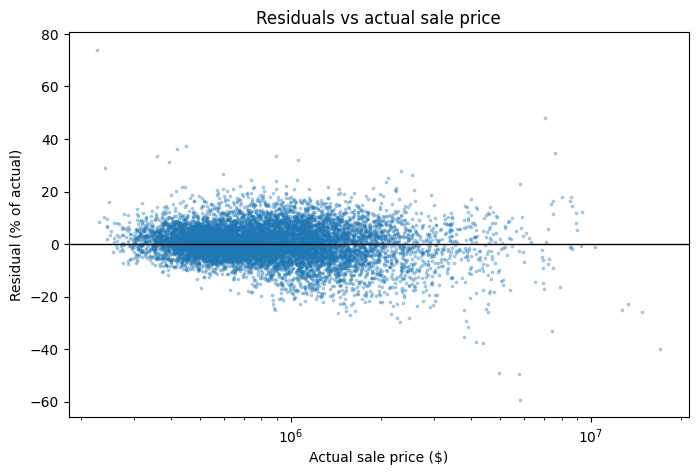

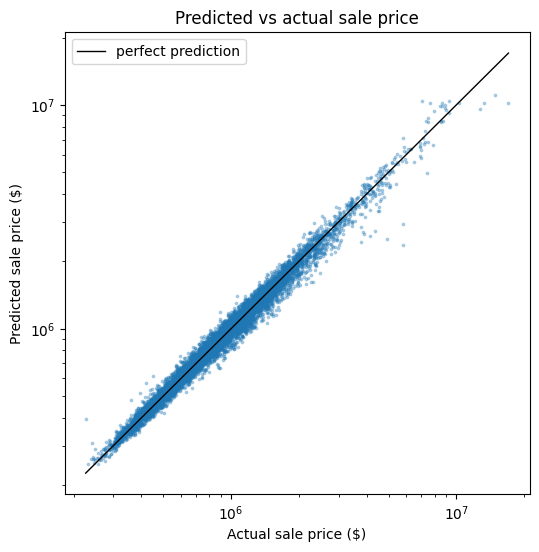

In [14]:
import diagnostics

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

In [16]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=20)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 388140.0]",504,14227.730159,-7027.103175,4.216702,3.297213,4.216702
"(388140.0, 440480.0]",503,17066.165010,-7541.671968,4.098027,3.191746,4.098027
"(440480.0, 482100.0]",505,17430.398020,-5006.611881,3.774118,2.977699,3.774118
"(482100.0, 521000.0]",503,19353.367793,-4143.343936,3.860388,3.232319,3.860388
"(521000.0, 558000.0]",503,20597.373757,-4664.745527,3.823307,3.229956,3.823307
"(558000.0, 597040.0]",503,23539.936382,-5515.391650,4.074403,3.212096,4.074403
"(597040.0, 643360.0]",503,25458.924453,-5552.013917,4.107101,3.436652,4.107101
"(643360.0, 692020.0]",504,29659.470238,-6587.942460,4.454228,3.530270,4.454228
"(692020.0, 747620.0]",503,33395.163022,-6495.520875,4.629768,3.714575,4.629768
